 Компания запустила новую версию лендинга с целью увеличения конверсии в покупку. Мы провели два эксперимента и собрали данные за 2 недели. Нам необходим полноценный статистический анализ результатов.

In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import zt_ind_solve_power
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

## Создание данных

In [181]:
"""
Скрипт для генерации синтетических данных для AA и AB тестирования
"""

import pandas as pd
import numpy as np
from datetime import datetime, timedelta


def generate_aa_test_data(
    n_users_per_group=10000,
    base_ctr=5.0,
    ctr_std=2.0,
    avg_views=100,
    views_std=20,
    random_seed=42,
    start_date=datetime(2025, 11, 1),
    distribution='normal'
):
    """
    Генерирует данные для AA теста с разными распределениями

    Параметры:
    ----------
    distribution : str
        Тип распределения для CTR:
        - 'normal' : нормальное распределение (по умолчанию)
        - 'uniform' : равномерное распределение
        - 'exponential' : экспоненциальное (скошенное вправо)
        - 'lognormal' : логнормальное (длинный хвост справа)
        - 'beta' : бета-распределение (для процентов/вероятностей)
        - 'bimodal' : бимодальное (два пика)
        - 'skewed' : скошенное (гамма-распределение)
    """
    np.random.seed(random_seed)

    data = []
    used_ids = set()

    for group in ['control', 'test']:
        for i in range(n_users_per_group):
            # Генерация уникального ID
            while True:
                user_id = f"{np.random.randint(100000, 999999)}"
                if user_id not in used_ids:
                    used_ids.add(user_id)
                    break

            date = start_date - timedelta(days=np.random.randint(0, 90))

            # Генерируем количество показов
            views = int(max(1, np.random.normal(avg_views, views_std)))

            # ГЕНЕРАЦИЯ CTR В ЗАВИСИМОСТИ ОТ РАСПРЕДЕЛЕНИЯ
            if distribution == 'normal':
                # Нормальное распределение (симметричное)
                ctr = np.random.normal(base_ctr, ctr_std)

            elif distribution == 'uniform':
                # Равномерное распределение
                half_range = ctr_std * np.sqrt(3)  # чтобы std был примерно ctr_std
                ctr = np.random.uniform(base_ctr - half_range, base_ctr + half_range)

            elif distribution == 'exponential':
                # Экспоненциальное (скошенное вправо)
                # Сдвигаем, чтобы среднее было base_ctr
                scale = ctr_std / 1.5
                ctr = np.random.exponential(scale) + (base_ctr - scale)

            elif distribution == 'lognormal':
                # Логнормальное (длинный хвост справа)
                sigma = 0.4
                mu = np.log(base_ctr) - sigma**2 / 2
                ctr = np.random.lognormal(mu, sigma)

            elif distribution == 'beta':
                # Бета-распределение (идеально для процентов)
                # Параметры подобраны так, чтобы среднее = base_ctr/100
                alpha = 5
                beta_param = alpha * (100 - base_ctr) / base_ctr
                ctr = np.random.beta(alpha, beta_param) * 100

            elif distribution == 'bimodal':
                # Бимодальное (два пика)
                if np.random.random() < 0.5:
                    ctr = np.random.normal(base_ctr - 2, ctr_std * 0.6)
                else:
                    ctr = np.random.normal(base_ctr + 2, ctr_std * 0.6)

            elif distribution == 'skewed':
                # Гамма-распределение (скошенное)
                shape = 4
                scale = base_ctr / shape
                ctr = np.random.gamma(shape, scale)

            else:
                raise ValueError(f"Неизвестное распределение: {distribution}")

            # Ограничиваем CTR в разумных пределах
            ctr = max(0, min(100, ctr))

            # Рассчитываем количество лайков
            likes = int(round(views * (ctr / 100)))
            likes = max(0, min(likes, views))

            data.append({
                'user_id': user_id,
                'date': date.strftime('%Y-%m-%d'),
                'group': group,
                'likes': likes,
                'views': views,
                'ctr': round(ctr, 2)
            })

    return pd.DataFrame(data)


def generate_ab_test_data(
    n_users_per_group=10000,
    control_ctr=5.0,
    test_ctr=6.0,
    ctr_std=2.0,
    avg_views=100,
    views_std=20,
    random_seed=42,
    start_date=datetime(2025, 11, 1),
    distribution='normal'
):
    """
    Генерирует данные для AB теста с разными распределениями
    """
    np.random.seed(random_seed)

    data = []
    used_ids = set()

    for group in ['control', 'test']:
        for i in range(n_users_per_group):
            # Генерация уникального ID
            while True:
                user_id = f"{np.random.randint(100000, 999999)}"
                if user_id not in used_ids:
                    used_ids.add(user_id)
                    break

            date = start_date + timedelta(days=np.random.randint(0, 14))

            # Генерируем количество показов
            views = int(max(1, np.random.normal(avg_views, views_std)))

            # Выбираем средний CTR в зависимости от группы
            mean_ctr = control_ctr if group == 'control' else test_ctr

            # ГЕНЕРАЦИЯ CTR В ЗАВИСИМОСТИ ОТ РАСПРЕДЕЛЕНИЯ
            if distribution == 'normal':
                ctr = np.random.normal(mean_ctr, ctr_std)

            elif distribution == 'uniform':
                half_range = ctr_std * np.sqrt(3)
                ctr = np.random.uniform(mean_ctr - half_range, mean_ctr + half_range)

            elif distribution == 'exponential':
                scale = ctr_std / 1.5
                ctr = np.random.exponential(scale) + (mean_ctr - scale)

            elif distribution == 'lognormal':
                sigma = 0.4
                mu = np.log(mean_ctr) - sigma**2 / 2
                ctr = np.random.lognormal(mu, sigma)

            elif distribution == 'beta':
                alpha = 5
                beta_param = alpha * (100 - mean_ctr) / mean_ctr
                ctr = np.random.beta(alpha, beta_param) * 100

            elif distribution == 'bimodal':
                if np.random.random() < 0.5:
                    ctr = np.random.normal(mean_ctr - 2, ctr_std * 0.6)
                else:
                    ctr = np.random.normal(mean_ctr + 2, ctr_std * 0.6)

            elif distribution == 'skewed':
                shape = 4
                scale = mean_ctr / shape
                ctr = np.random.gamma(shape, scale)

            else:
                raise ValueError(f"Неизвестное распределение: {distribution}")

            ctr = max(0, min(100, ctr))

            likes = int(round(views * (ctr / 100)))
            likes = max(0, min(likes, views))

            data.append({
                'user_id': user_id,
                'date': date.strftime('%Y-%m-%d'),
                'group': group,
                'likes': likes,
                'views': views,
                'ctr': round(ctr, 2)
            })

    return pd.DataFrame(data)

In [182]:
# Параметры генерации
N_USERS = 3000  # пользователей на группу
BASE_CTR = 5.0  # 5% средний CTR
CONTROL_CTR = 5.0  # 5% средний CTR в контроле
TEST_CTR = 5.2  # 6% средний CTR в тесте (+20% относительный лифт)
CTR_STD = 2.0  # стандартное отклонение CTR (в процентах)
AVG_VIEWS = 100  # среднее количество показов
VIEWS_STD = 20  # стандартное отклонение показов

# Генерируем AA тест
aa_df = generate_aa_test_data(
    n_users_per_group=N_USERS,
    base_ctr=BASE_CTR,
    ctr_std=CTR_STD,
    avg_views=AVG_VIEWS,
    views_std=VIEWS_STD,
    random_seed=42,
    distribution='normal'
)

# Генерируем AB тест
ab_df = generate_ab_test_data(
    n_users_per_group=N_USERS,
    control_ctr=CONTROL_CTR,
    test_ctr=TEST_CTR,
    ctr_std=CTR_STD,
    avg_views=AVG_VIEWS,
    views_std=VIEWS_STD,
    random_seed=42,
    distribution='normal'
)

# Сохраняем в CSV
aa_df.to_csv('aa_test_data.csv', index=False)
ab_df.to_csv('ab_test_data.csv', index=False)


In [183]:
file_path_aa = "aa_test_data.csv"
file_path_ab = "ab_test_data.csv"

df_aa = pd.read_csv(file_path_aa)
df_ab = pd.read_csv(file_path_ab)

df_aa.head()

,user_id,date,group,likes,views,ctr
0,221958,2025-09-11,control,4,77,5.64
1,621430,2025-08-19,control,2,59,4.01
2,291335,2025-10-09,control,5,90,5.33
3,421879,2025-10-03,control,3,88,3.95
4,335796,2025-09-30,control,1,104,1.17


In [120]:
df_aa.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   user_id  6000 non-null   int64  
 1   date     6000 non-null   object 
 2   group    6000 non-null   object 
 3   likes    6000 non-null   int64  
 4   views    6000 non-null   int64  
 5   ctr      6000 non-null   float64
dtypes: float64(1), int64(3), object(2)
memory usage: 281.4+ KB


In [121]:
df_aa.describe()

,user_id,likes,views,ctr
count,6000.000000,6000.000000,6000.000000,6000.000000
mean,551753.630167,4.988500,99.608000,5.013262
std,261099.541410,2.262938,20.230725,1.971747
min,100056.000000,0.000000,26.000000,0.000000
25%,322649.000000,3.000000,86.000000,3.660000
50%,554334.000000,5.000000,100.000000,5.050000
75%,776399.500000,6.000000,113.000000,6.390000
max,999993.000000,15.000000,169.000000,12.710000


In [176]:
df_aa.isnull().sum()

,0
user_id,0
date,0
group,0
likes,0
views,0
ctr,0


In [175]:
df_aa.duplicated().sum()

np.int64(0)

In [179]:
df_aa['group'].value_counts()

,count
group,
control,3000
test,3000


In [184]:
df_ab['group'].value_counts()

,count
group,
control,3000
test,3000


## АА тест

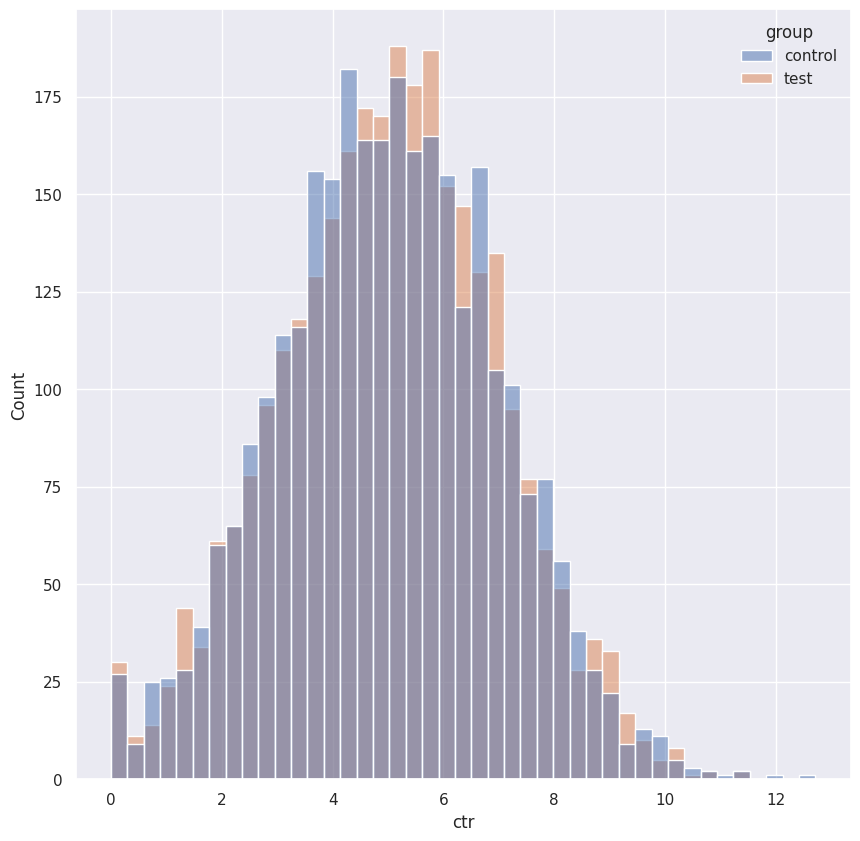

In [123]:
sns.set(rc={'figure.figsize':(10, 10)})
groups = sns.histplot(data=df_aa,
                    x         = 'ctr',
                    hue       = "group",
                    kde       = False,
                    alpha     = 0.5)

Расределение экспериментальных групп практически совпадает

In [124]:
def bootstrap_aa(n_bootstrap: int = 10000,
                 B: int = 500,):
    pvalues = []
    for _ in range(n_bootstrap):
        group_1 = df_aa[df_aa['group'] == 'control']['ctr'].sample(B, replace=False).tolist()
        group_2 = df_aa[df_aa['group'] == 'test']['ctr'].sample(B, replace=False).tolist()
        pvalues.append(stats.ttest_ind(group_1, group_2, equal_var=False)[1])

    return pvalues

<Axes: ylabel='Count'>

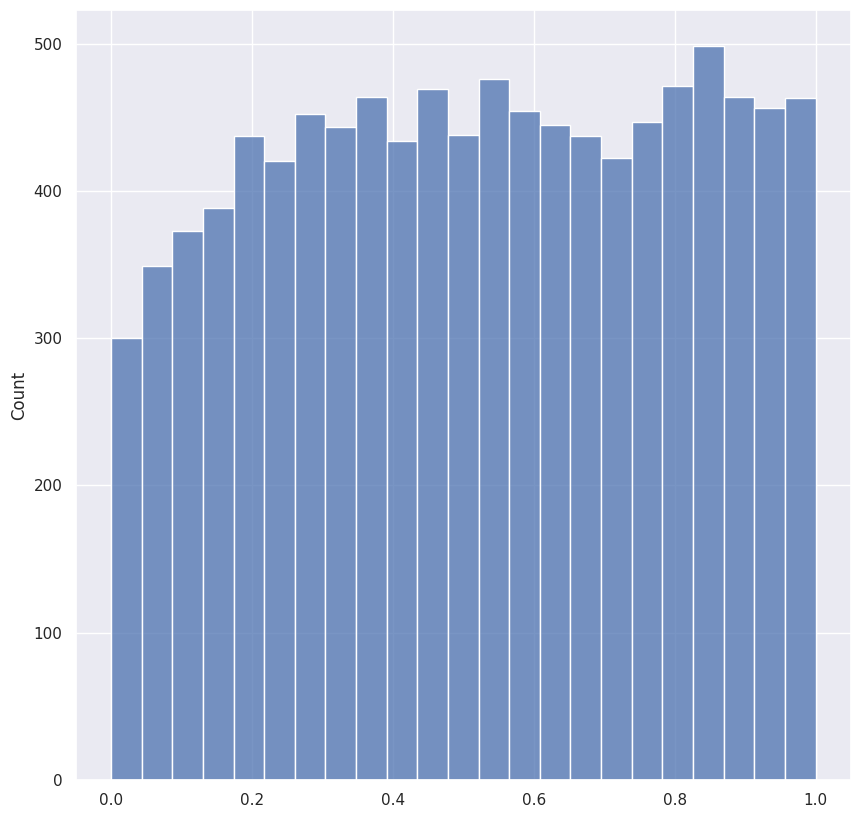

In [125]:
pvalues=bootstrap_aa()
sns.histplot(pvalues)

In [126]:
perc = sum([1 for i in pvalues if i <= 0.05]) / 10000 * 100
print(f'{perc}% is the percent of p-values which are less than 0.05 ')

3.53% is the percent of p-values which are less than 0.05 


**Вывод:**
Статистически значимые различия получаем в < 5% , что соответствует ошибке I рода.


## AB тест




**Наш сайт заказал дизайн в студии Артемия Лебедева**

**H₀ (нулевая гипотеза):** CTR в группах одинаковый

**H₁ (альтернативная гипотеза):** CTR в группах различается  

**Уровень значимости:** 0.05

In [127]:
group_a = df_ab[df_ab['group'] == 'control']['ctr'] # контрольная группа
group_b = df_ab[df_ab['group'] == 'test']['ctr'] # экпериментальная группа

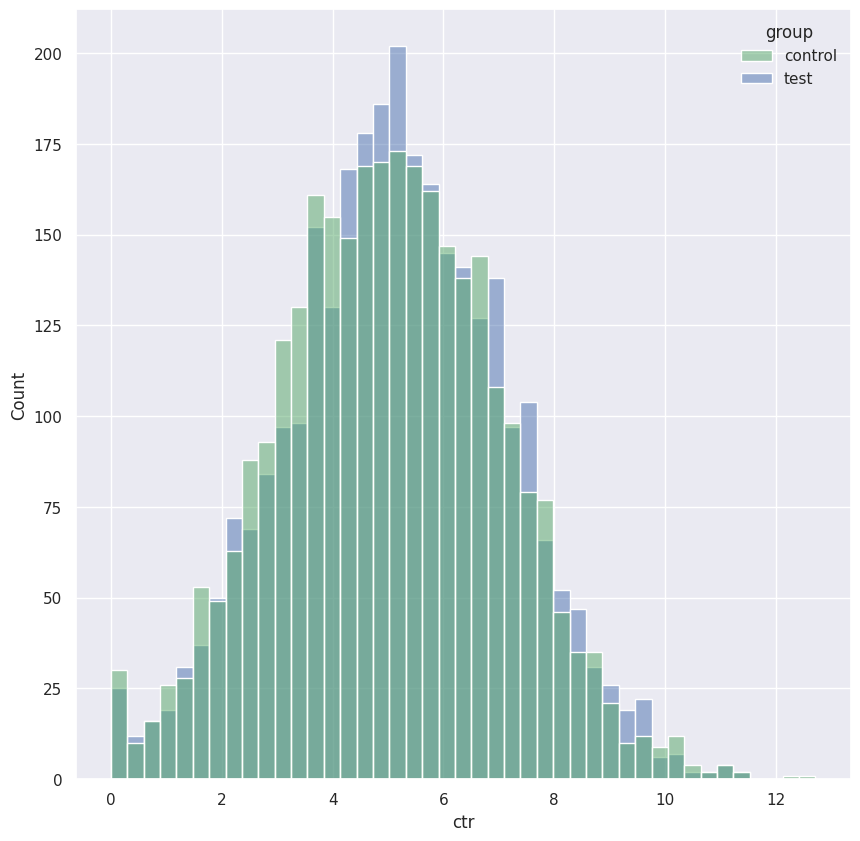

In [128]:
sns.set(rc={'figure.figsize':(10, 10)})
sns.histplot(data=df_ab,
            x          = 'ctr',
            hue        = 'group',
            palette    = ['g', 'b'],
            kde        = False,
            alpha      = 0.5);

Распределение обеих групп похоже на нормальное. В тестовой выборке график смещен вправо

In [129]:
stats.ttest_ind(group_a, group_b, equal_var=False)

TtestResult(statistic=np.float64(-2.4546320176728016), pvalue=np.float64(0.014131096415433522), df=np.float64(5996.96085367693))

In [130]:
group_a.mean(), group_b.mean()

(np.float64(5.013423333333334), np.float64(5.1396033333333335))

In [131]:
df_ab.head()

,user_id,date,group,likes,views,ctr
0,221958,2025-11-04,control,4,77,5.64
1,621430,2025-11-11,control,2,59,4.01
2,291335,2025-11-08,control,5,90,5.33
3,421879,2025-11-12,control,4,100,4.14
4,970910,2025-11-10,control,4,94,4.67


In [132]:
stats.mannwhitneyu(group_a, group_b, alternative='two-sided')

MannwhitneyuResult(statistic=np.float64(4323858.0), pvalue=np.float64(0.008650963414683258))

In [133]:
def my_mannwhitneyu(x, y, alternative='two-sided'):
  x = np.asarray(x)
  y = np.asarray(y)

  n1 = len(x)
  n2 = len(y)

  combined = np.concatenate([x, y])
  ranks = stats.rankdata(combined)
  rank_sum_x = np.sum(ranks[:n1])
  rank_sum_y = np.sum(ranks[n1:])

  U1 =  n1 * n2 + (n1 * (n1 + 1) / 2) - rank_sum_x
  U2 = n1 * n2 + (n2 * (n2 + 1) / 2) - rank_sum_y
  # print(U1, U2)
  U = min(U1, U2)
  # print(U)
  mu_U = n1 * n2 / 2
  sigma_U = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)

  z = (U - mu_U) / sigma_U

  if alternative == 'two-sided':
    pvalue = 2 * stats.norm.cdf(z)
  elif alternative == 'less':
    pvalue = stats.norm.cdf(z)
  elif alternative == 'greater':
    pvalue = 1 - stats.norm.cdf(z)

  return U, pvalue

my_mannwhitneyu(group_a, group_b, alternative='two-sided')

(np.float64(4323858.0), np.float64(0.00865088182061757))

In [134]:
def my_ttest_ind(a, b, equal_var=False):
  """
  equal_var : bool
      True - Student's t-test (равные дисперсии)
      False - Welch's t-test (разные дисперсии)
  """
  n1 = len(a)
  n2 = len(b)

  mean1 = np.mean(a)
  mean2 = np.mean(b)

  var1 = np.var(a, ddof=1)
  var2 = np.var(b, ddof=1)

  if equal_var:
      # Student's t-test
      # Объединенная дисперсия sp
      pooled_var = ((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2)

      # Стандартная ошибка разности средних
      se = np.sqrt(pooled_var * (1/n1 + 1/n2))

      # Степени свободы
      df = n1 + n2 - 2

  else:
      # Welch's t-test (разные дисперсии)
      # Стандартная ошибка разности средних
      se = np.sqrt(var1/n1 + var2/n2)

      # Степени свободы по формуле Уэлча-Саттертуэйта
      numerator = (var1/n1 + var2/n2) ** 2
      denominator = (var1/n1)**2 / (n1-1) + (var2/n2)**2 / (n2-1)
      df = numerator / denominator

  # T-статистика
  t_statistic = (mean1 - mean2) / se

  # P-value (двусторонний тест)
  # Используем t-распределение Стьюдента
  p_value = 2 * (1 - stats.t.cdf(abs(t_statistic), df))
  print(f"TtestResult(statistic={t_statistic}, pvalue={p_value}, df={df})")
  return t_statistic, p_value, df

my_ttest_ind(group_a, group_b, equal_var=False)

TtestResult(statistic=-2.4546320176728016, pvalue=0.01413109641543353, df=5996.960853676929)


(np.float64(-2.4546320176728016),
 np.float64(0.01413109641543353),
 5996.960853676929)

## Данные распределены ненормально

- 'normal' : нормальное распределение (по умолчанию)

- 'uniform' : равномерное распределение

- 'exponential' : экспоненциальное (скошенное вправо)

- 'lognormal' : логнормальное (длинный хвост справа)

- 'beta' : бета-распределение (для процентов/вероятностей)

- 'bimodal' : бимодальное (два пика)

- 'skewed' : скошенное (гамма-распределение)

In [267]:
# Параметры генерации
N_USERS = 500  # пользователей на группу
BASE_CTR = 5.0  # % средний CTR
CONTROL_CTR = 5.0  # % средний CTR в контроле
TEST_CTR = 5.2  # % средний CTR в тесте
CTR_STD = 2.0  # стандартное отклонение CTR (в процентах)
AVG_VIEWS = 100  # среднее количество показов
VIEWS_STD = 20  # стандартное отклонение показов

# Генерируем AB тест
ab_df = generate_ab_test_data(
    n_users_per_group=N_USERS,
    control_ctr=CONTROL_CTR,
    test_ctr=TEST_CTR,
    ctr_std=CTR_STD,
    avg_views=AVG_VIEWS,
    views_std=VIEWS_STD,
    random_seed=42,
    distribution='normal'
)

# Генерируем AB тест, распределение экспоненциальное
ab_df_exponential = generate_ab_test_data(
    n_users_per_group=N_USERS,
    control_ctr=CONTROL_CTR,
    test_ctr=TEST_CTR,
    ctr_std=CTR_STD,
    avg_views=AVG_VIEWS,
    views_std=VIEWS_STD,
    random_seed=42,
    distribution='lognormal'
)

In [268]:
ab_df_exponential_test = ab_df_exponential[ab_df_exponential["group"] == 'test']
ab_df_normal_control = ab_df[ab_df["group"] == 'control']

In [269]:
df_ab_1 = pd.concat([ab_df_exponential_test, ab_df_normal_control], ignore_index=True)

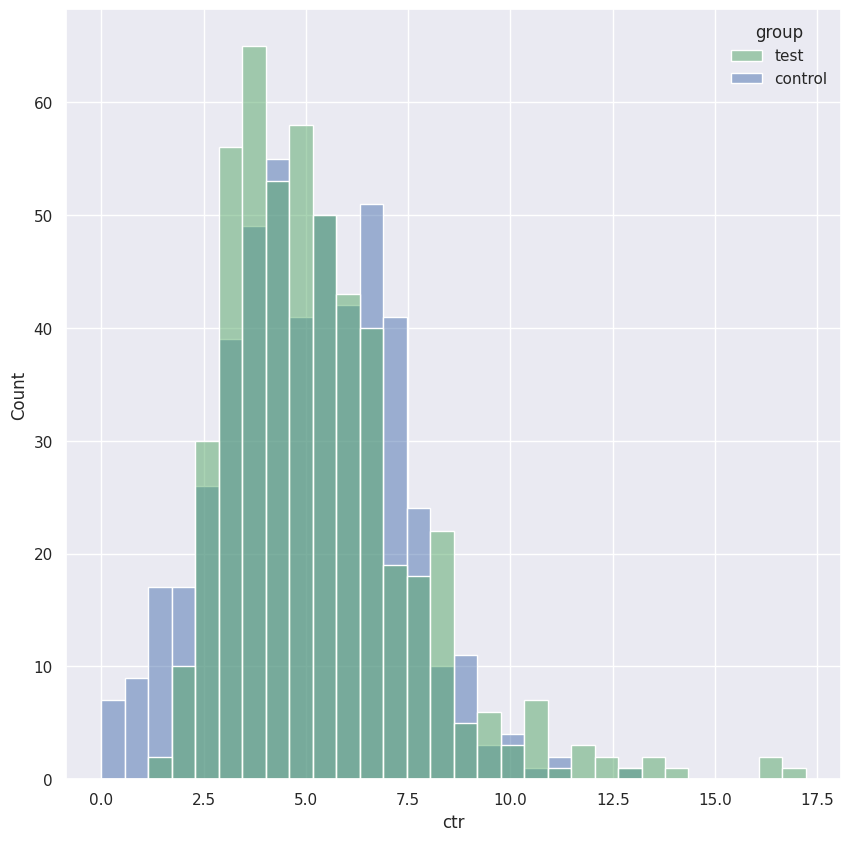

In [270]:
sns.set(rc={'figure.figsize':(10, 10)})
sns.histplot(data=df_ab_1,
            x          = 'ctr',
            hue        = 'group',
            palette    = ['g', 'b'],
            kde        = False,
            alpha      = 0.5);

In [274]:
stats.shapiro(df_ab_1[df_ab_1["group"] == 'test']['ctr'])

ShapiroResult(statistic=np.float64(0.898853053137294), pvalue=np.float64(1.13975987123816e-17))

pvalue < 0,05 % что говорит о ненормальном распределении тестовой выборки

In [271]:
group_a = df_ab_1[df_ab_1["group"] == 'control']['ctr']
group_b = df_ab_1[df_ab_1["group"] == 'test']['ctr']

In [275]:
# использование т-теста некорректно, так как не выполняется условие нормального распределения
stats.ttest_ind(group_a, group_b, equal_var=False)

TtestResult(statistic=np.float64(-2.1208822990760137), pvalue=np.float64(0.034179606620751465), df=np.float64(990.6747817026645))

In [273]:
stats.mannwhitneyu(group_a, group_b, alternative='two-sided')

MannwhitneyuResult(statistic=np.float64(122252.0), pvalue=np.float64(0.5474082808997749))

Тест Манна-Уитни pvalue > 0,05 что не дает нам возможности отвергнуть нулевую гипотезу